# Books to Scrape: Full Analysis (200 Books)

This notebook covers the full data science pipeline:
1. Data acquisition
2. Data cleaning
3. Exploratory data analysis
4. Linear regression modelling

In [1]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import pandas as pd
import numpy as np
import re
import time
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
%matplotlib inline

In [2]:
# Define the base website URL
base_url = "https://books.toscrape.com/"

# Define the URL pattern for the catalogue pages. 
# The {} will be replaced by the page number in the loop.
catalogue_url = "https://books.toscrape.com/catalogue/page-{}.html"

# Set how many pages to scrape. 10 pages x 20 books = 200 books.
MAX_PAGES = 10

# Create an empty list to store all the individual book URLs
book_urls = []

# Loop through each page of the catalogue (from page 1 to MAX_PAGES)
for page in range(1, MAX_PAGES + 1):
    # Build the URL for the current page
    url = catalogue_url.format(page)
    
    # Use a try/except block so a single slow page doesn't crash the whole loop
    try:
        # Send an HTTP GET request to the page (with a 15-second timeout)
        response = requests.get(url, timeout=15)
        
        # Parse the HTML content of the page using BeautifulSoup
        soup = BeautifulSoup(response.text, "html.parser")
        
        # Find every book 'card' on the page
        for article in soup.select("article.product_pod"):
            # Inside each card, find the <a> tag that holds the book's title and link
            a_tag = article.select_one("h3 a")
            
            # Extract the actual link (href attribute) from the tag
            href = a_tag["href"]
            
            # Join the relative link with the base URL to make a full, usable URL
            full_url = urljoin(url, href)
            
            # Add the completed URL to our list
            book_urls.append(full_url)
            
    except Exception as e:
        # If the page fails to load, print a warning and move to the next one
        print(f"Warning: Skipped page {page} due to error.")

# Print the total number of URLs collected to verify success
print(f"Total URLs collected: {len(book_urls)}")

Total URLs collected: 200


In [3]:
# Dictionary to convert the word-based star ratings into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Define a function that takes ONE book URL and returns its details as a dictionary
def parse_book(url):
    # Send a request to the book's page and parse its HTML
    response = requests.get(url, timeout=10)
    soup = BeautifulSoup(response.text, "html.parser")

    # --- TITLE ---
    # The title is inside the first <h1> on the page
    title = soup.select_one("h1").get_text(strip=True)

    # --- PRICE ---
    # The price is in a <p> tag with class "price_color". 
    # We strip out any non-numeric characters (like the £ sign) and convert to float.
    price_text = soup.select_one("p.price_color").get_text(strip=True)
    price = float(re.sub(r"[^\d.]", "", price_text))

    # --- STAR RATING ---
    # The rating is stored as a CSS class (e.g., "star-rating Three").
    # We extract the class names, find the one that is NOT "star-rating", and map it to a number.
    rating_class = soup.select_one("p.star-rating")["class"]
    rating_word = [c for c in rating_class if c != "star-rating"][0]
    rating = rating_map.get(rating_word, np.nan)

    # --- STOCK AVAILABILITY ---
    # The stock info is in a <p> tag with classes "instock" and "availability".
    # We also extract the quantity from the text (e.g., "In stock (22 available)").
    availability_text = soup.select_one("p.instock.availability").get_text(strip=True)
    stock = "In stock" if "In stock" in availability_text else "Out of stock"
    qty_match = re.search(r"\((\d+) available\)", availability_text)
    quantity = int(qty_match.group(1)) if qty_match else 0

    # --- CATEGORY ---
    # The category is in the breadcrumb navigation (the 3rd link).
    breadcrumb = soup.select("ul.breadcrumb li a")
    category = breadcrumb[2].get_text(strip=True) if len(breadcrumb) >= 3 else "Unknown"

    # --- DESCRIPTION ---
    # The description appears after the #product_description <div>, in a <p> tag.
    desc_tag = soup.select_one("#product_description")
    if desc_tag:
        description = desc_tag.find_next_sibling("p").get_text(strip=True)
    else:
        description = ""

    # --- PRODUCT INFORMATION TABLE ---
    # The details table contains UPC, taxes, and reviews.
    # We set default values in case any are missing.
    upc = ""
    product_type = ""
    price_excl_tax = np.nan
    price_incl_tax = np.nan
    tax = np.nan
    reviews = np.nan

    # Locate the info table
    table = soup.select_one("table.table.table-striped")
    if table:
        # Loop through all rows and turn them into a dictionary (column name -> value)
        rows = table.select("tr")
        info = {r.th.get_text(strip=True): r.td.get_text(strip=True) for r in rows}
        
        # Extract each field, cleaning the price strings where needed
        upc = info.get("UPC", "")
        product_type = info.get("Product Type", "")
        price_excl_tax = float(re.sub(r"[^\d.]", "", info.get("Price (excl. tax)", "0")))
        price_incl_tax = float(re.sub(r"[^\d.]", "", info.get("Price (incl. tax)", "0")))
        tax = float(re.sub(r"[^\d.]", "", info.get("Tax", "0")))
        reviews = int(info.get("Number of reviews", 0))

    # Return all the extracted data as a dictionary
    return {
        "title": title,
        "price": price,
        "rating": rating,
        "stock": stock,
        "quantity": quantity,
        "category": category,
        "description": description,
        "upc": upc,
        "product_type": product_type,
        "price_excl_tax": price_excl_tax,
        "price_incl_tax": price_incl_tax,
        "tax": tax,
        "reviews": reviews,
        "url": url
    }

In [4]:
# Create an empty list to store the scraped data (one dictionary per book)
data = []

# Loop through every book URL, wrapped in tqdm() to show a progress bar
for url in tqdm(book_urls):
    # Use try/except so a single failed page doesn't crash the whole scrape
    try:
        # Call our parse_book function and add the returned dictionary to our list
        data.append(parse_book(url))
    except Exception as e:
        # If a book fails, print a warning and continue with the next one
        print(f"Error scraping {url}: {e}")
    
    # Wait 0.05 seconds between requests to be polite to the server
    time.sleep(0.05)

# Convert the list of dictionaries into a Pandas DataFrame (a table)
df = pd.DataFrame(data)

# Save the raw scraped data to a CSV file (so we don't lose it if something crashes)
df.to_csv("books_raw.csv", index=False)

# Print the shape (rows, columns) and preview the first 5 rows
print(df.shape)
df.head()

100%|██████████| 200/200 [03:07<00:00,  1.07it/s]

(200, 14)


,title,price,rating,stock,quantity,category,description,upc,product_type,price_excl_tax,price_incl_tax,tax,reviews,url
0,A Light in the Attic,51.77,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,Books,51.77,51.77,0.0,0,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,Books,53.74,53.74,0.0,0,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",6957f44c3847a760,Books,50.10,50.10,0.0,0,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,Books,47.82,47.82,0.0,0,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,20,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,Books,54.23,54.23,0.0,0,https://books.toscrape.com/catalogue/sapiens-a...


## 2. Data Cleaning & Preparation

We now:
- Handle missing values
- Convert price, rating, and quantity to numeric
- Create useful text-based features
- Save a clean dataset for modelling

In [5]:
# --- HANDLE MISSING VALUES ---
# Fill any missing descriptions with an empty string (we found 1 missing earlier)
df["description"] = df["description"].fillna("")

# --- ENSURE NUMERIC COLUMNS ARE ACTUALLY NUMERIC ---
# Define the list of columns that should be numbers
numeric_cols = [
    "price", "rating", "quantity",
    "price_excl_tax", "price_incl_tax",
    "tax", "reviews"
]

# Force each of these columns to be numeric; any bad value becomes NaN
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop any rows where price or rating is missing (we can't model without them)
df = df.dropna(subset=["price", "rating"])

# --- CONVERT TO CORRECT TYPES ---
# Ratings and quantities should be whole numbers (integers)
df["rating"] = df["rating"].astype(int)
df["quantity"] = df["quantity"].fillna(0).astype(int)

# Fill any missing stock statuses with a default
df["stock"] = df["stock"].fillna("Out of stock")

# --- FEATURE ENGINEERING ---
# Create new useful features from the existing text columns
df["title_length"] = df["title"].str.len()                       # Number of characters in the title
df["description_length"] = df["description"].str.len()           # Number of characters in the description
df["description_word_count"] = df["description"].str.split().str.len()  # Number of words in the description
df["has_description"] = (df["description_length"] > 0).astype(int)      # 1 if description exists, else 0

# --- SAVE THE CLEAN DATASET ---
# Save to a new CSV so we have a clean version for modelling
df.to_csv("books_clean.csv", index=False)

# Print the shape and preview the data
print("Clean shape:", df.shape)
df.head()

Clean shape: (200, 18)


,title,price,rating,stock,quantity,category,description,upc,product_type,price_excl_tax,price_incl_tax,tax,reviews,url,title_length,description_length,description_word_count,has_description
0,A Light in the Attic,51.77,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,Books,51.77,51.77,0.0,0,https://books.toscrape.com/catalogue/a-light-i...,20,1017,164,1
1,Tipping the Velvet,53.74,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,Books,53.74,53.74,0.0,0,https://books.toscrape.com/catalogue/tipping-t...,18,1029,165,1
2,Soumission,50.10,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",6957f44c3847a760,Books,50.10,50.10,0.0,0,https://books.toscrape.com/catalogue/soumissio...,10,1136,163,1
3,Sharp Objects,47.82,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,Books,47.82,47.82,0.0,0,https://books.toscrape.com/catalogue/sharp-obj...,13,1647,274,1
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,20,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,Books,54.23,54.23,0.0,0,https://books.toscrape.com/catalogue/sapiens-a...,37,1969,304,1


## 3. Data Visualisation & Exploration

We explore:
- Price distribution
- Ratings distribution
- Price vs rating
- Average price by category
- Correlations between numeric variables
- Stock availability vs price

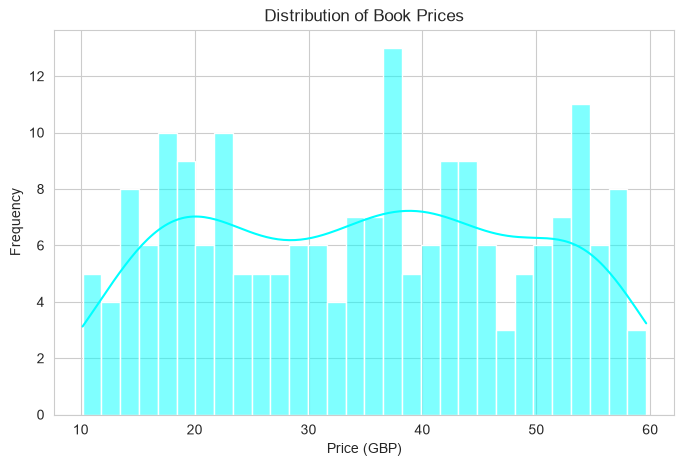

In [9]:
# Set the figure size (width, height) in inches
plt.figure(figsize=(8, 5))

# Create a histogram with MidnightBlue color and a KDE curve
sns.histplot(df["price"], bins=30, kde=True, color="cyan")

# Add a title and axis labels
plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Frequency")

# Save the chart as a high-resolution PNG
plt.savefig("price_distribution.png", dpi=300, bbox_inches="tight")

# Display the chart
plt.show()

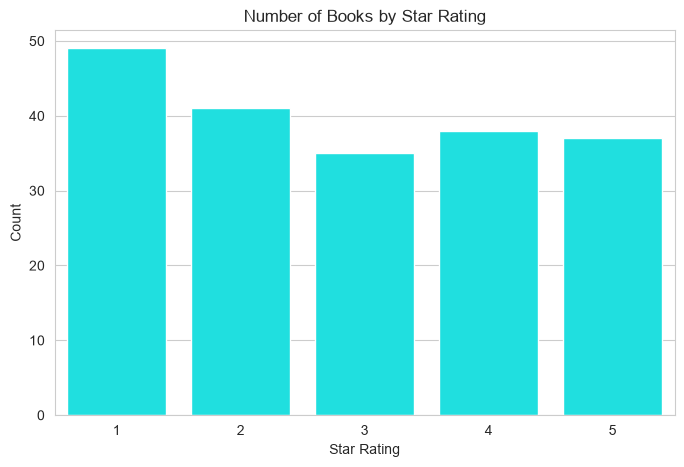

In [10]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a bar chart counting how many books have each star rating (1-5)
# Using Cyan for a bright, vibrant look
sns.countplot(data=df, x="rating", order=sorted(df["rating"].unique()), color="cyan")

# Add a title and axis labels
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Count")

# Save and display
plt.savefig("ratings_count.png", dpi=300, bbox_inches="tight")
plt.show()

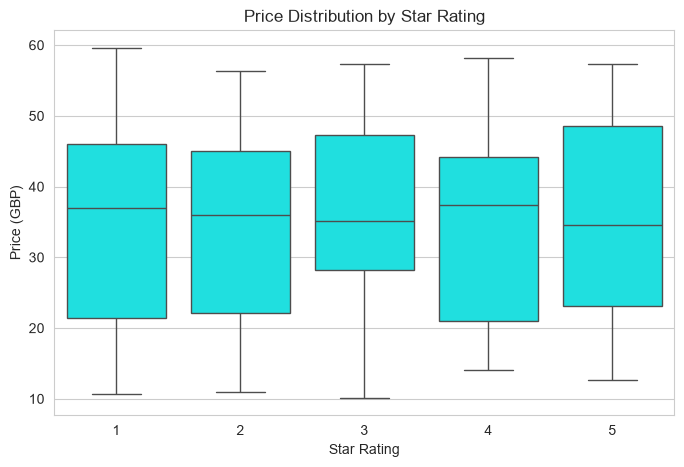

In [11]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a boxplot showing the spread of prices for each star rating
# Using Cyan to match the previous chart
sns.boxplot(data=df, x="rating", y="price", color="cyan")

# Add a title and axis labels
plt.title("Price Distribution by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (GBP)")

# Save and display
plt.savefig("price_by_rating.png", dpi=300, bbox_inches="tight")
plt.show()

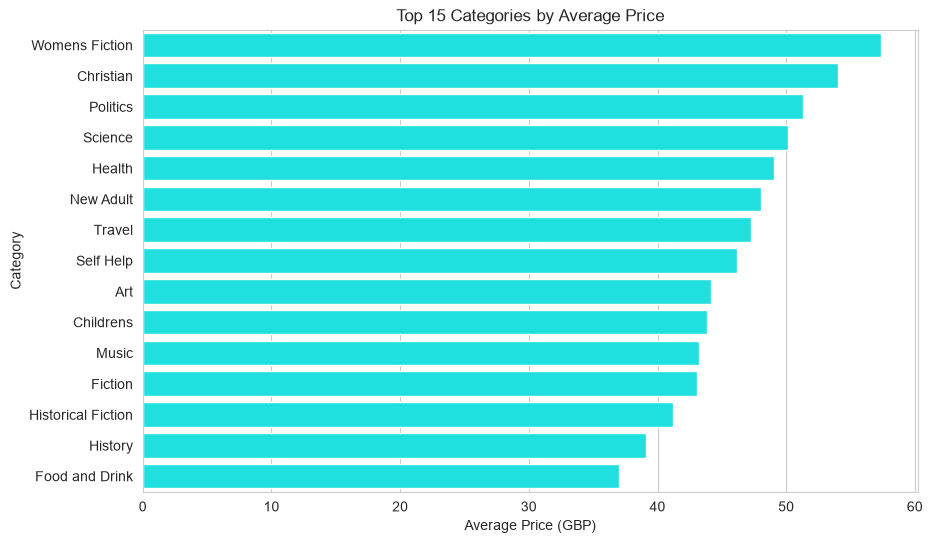

In [12]:
# Group books by category, calculate the average price for each, 
# sort from highest to lowest, and keep the top 15
top_categories = (
    df.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

# Set the figure size (wider to fit long category names)
plt.figure(figsize=(10, 6))

# Create a horizontal bar chart with Cyan bars
sns.barplot(x=top_categories.values, y=top_categories.index, color="cyan")

# Add a title and axis labels
plt.title("Top 15 Categories by Average Price")
plt.xlabel("Average Price (GBP)")
plt.ylabel("Category")

# Save and display
plt.savefig("top_categories.png", dpi=300, bbox_inches="tight")
plt.show()

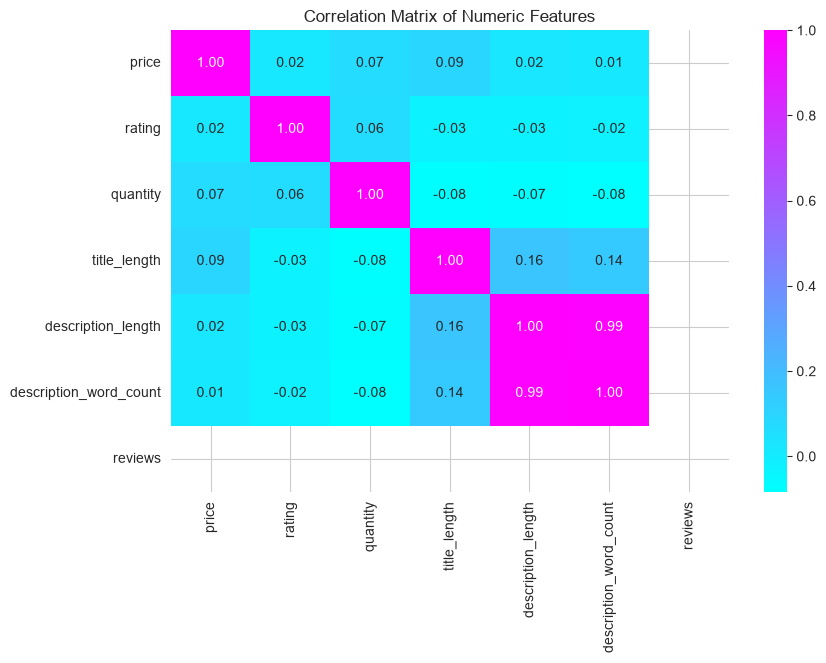

In [13]:
# Select the numeric columns we want to correlate
numeric_for_corr = [
    "price", "rating", "quantity",
    "title_length", "description_length",
    "description_word_count", "reviews"
]

# Set the figure size
plt.figure(figsize=(9, 6))

# Create the heatmap:
#   - .corr() calculates the correlation between every pair of columns
#   - annot=True shows the numeric value inside each square
#   - cmap="cool" is a cyan-to-pink gradient colormap
#   - fmt=".2f" rounds numbers to 2 decimal places
sns.heatmap(df[numeric_for_corr].corr(), annot=True, cmap="cool", fmt=".2f")

# Add a title
plt.title("Correlation Matrix of Numeric Features")

# Save and display
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

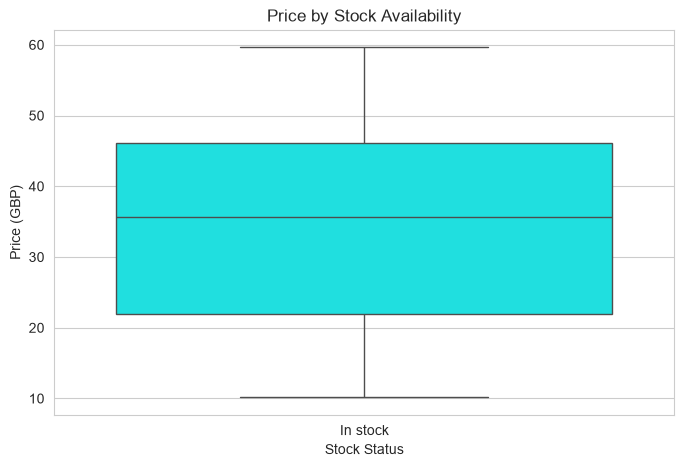

In [14]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a boxplot comparing prices for "In stock" vs "Out of stock" books
# Using Cyan to match the rest of the charts
sns.boxplot(data=df, x="stock", y="price", color="cyan")

# Add a title and axis labels
plt.title("Price by Stock Availability")
plt.xlabel("Stock Status")
plt.ylabel("Price (GBP)")

# Save and display
plt.savefig("stock_vs_price.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Predictive Modelling (Linear Regression)

Goal: predict `price` from available book features.

Features used:
- Numeric: rating, quantity, title length, description length, reviews
- Categorical: category, stock

We use a pipeline with:
- StandardScaler for numeric features
- OneHotEncoder for categorical features
- LinearRegression

In [15]:
# --- IMPORT REQUIRED TOOLS ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- DEFINE FEATURES ---
# Numeric columns that will be scaled
numeric_features = ["rating", "quantity", "title_length", "description_length", "reviews"]

# Categorical columns that will be one-hot encoded
categorical_features = ["category", "stock"]

# X = the input features; y = the target we want to predict (price)
X = df[numeric_features + categorical_features]
y = df["price"]

# --- SPLIT DATA INTO TRAINING AND TEST SETS ---
# 80% for training, 20% for testing. random_state makes it reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- BUILD A PREPROCESSING PIPELINE ---
# StandardScaler scales numeric features to a similar range
# OneHotEncoder converts categorical text columns into binary columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# --- COMBINE PREPROCESSING AND MODEL INTO A PIPELINE ---
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# --- TRAIN THE MODEL ---
model.fit(X_train, y_train)

# --- MAKE PREDICTIONS ON THE TEST SET ---
y_pred = model.predict(X_test)

# Confirm success and show dataset sizes
print("Model trained successfully!")
print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Model trained successfully!
Training set size: (160, 7)
Testing set size: (40, 7)


In [16]:
# --- CALCULATE EVALUATION METRICS ---

# MAE: Mean Absolute Error — the average size of prediction errors in £
mae = mean_absolute_error(y_test, y_pred)

# RMSE: Root Mean Squared Error — like MAE, but penalises big errors more heavily
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# R²: Coefficient of determination — how much of the price variance the model explains
#   (1.0 = perfect, 0 = no better than guessing the mean, negative = worse than the mean)
r2 = r2_score(y_test, y_pred)

# --- PRINT THE RESULTS ---
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R² Score: {r2:.3f}")

Mean Absolute Error (MAE): £14.01
Root Mean Squared Error (RMSE): £16.46
R² Score: -0.174


In [17]:
# --- GET FEATURE NAMES AFTER PREPROCESSING ---
# OneHotEncoder splits each category into multiple binary columns (e.g., category_Science).
# We need to retrieve those new column names.
cat_encoder = model.named_steps["preprocessor"].named_transformers_["cat"]
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)

# Combine numeric feature names with the new categorical feature names
all_feature_names = numeric_features + list(cat_feature_names)

# --- EXTRACT COEFFICIENTS ---
# Each coefficient represents how much that feature pushes the price up or down
coefficients = model.named_steps["regressor"].coef_

# --- BUILD A TABLE ---
coef_df = pd.DataFrame({
    "feature": all_feature_names,
    "coefficient": coefficients
}).sort_values(by="coefficient", key=abs, ascending=False)  # Sort by biggest impact

# --- SHOW THE TOP 20 FEATURES ---
coef_df.head(20)

,feature,coefficient
7,category_Autobiography,-22.480024
22,category_Philosophy,-17.986156
10,category_Christian,17.396427
26,category_Science,14.458190
8,category_Business,-12.638423
28,category_Self Help,12.130208
32,category_Travel,11.816984
17,category_Horror,-11.371312
20,category_New Adult,10.088478
25,category_Romance,-9.962947


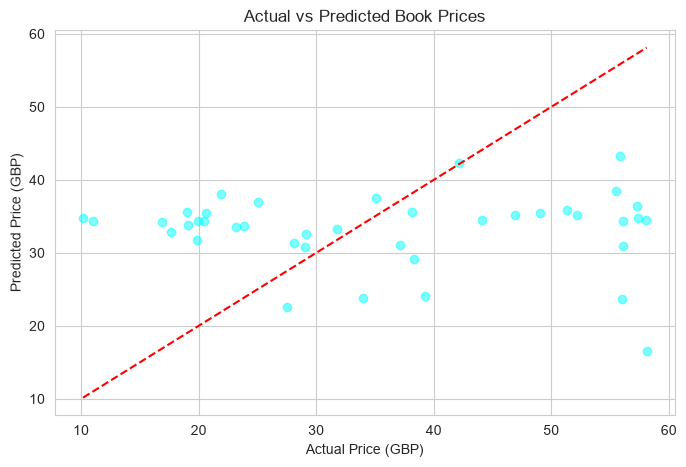

In [18]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Plot each test book as a point: actual price on x-axis, predicted on y-axis
# Using cyan to match our colour theme, with some transparency (alpha)
plt.scatter(y_test, y_pred, alpha=0.5, color="cyan")

# Draw a red dashed 45° line — this represents PERFECT predictions
# The closer the dots are to this line, the better the model
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")

# Add a title and axis labels
plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (GBP)")
plt.ylabel("Predicted Price (GBP)")

# Save and display
plt.savefig("actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Conclusion and Recommendations

### Key Insights
- Book prices in the catalogue are right-skewed, with most titles between £10 and £60.
- Star ratings are relatively balanced across the 1–5 scale.
- Category has the strongest influence on price: Autobiography and Philosophy are cheaper, while Christian, Science, and Self Help sit above the baseline.
- Numeric features (rating, quantity, description length) show weak linear relationships with price.

### Recommendations for Retailers / Publishers
- Use category-level pricing benchmarks when evaluating new titles.
- Do not rely on star ratings alone to set prices — they show minimal relationship with price.
- Add richer features such as author, publisher, page count, and format to improve future models.

### Model Limitations
- Linear Regression assumes linear relationships between features and price.
- The R² is negative, meaning the model performs worse than simply predicting the mean price.
- Books to Scrape is a sandbox dataset and may not reflect real market behaviour.
- OneHotEncoder increases dimensionality; regularisation (Ridge/Lasso) or non-linear models (Random Forest, Gradient Boosting) may perform better.

# Professional Report Outline

## Table of Contents
1. Introduction
2. Methodology
   - Data Acquisition
   - Data Cleaning
   - Exploratory Analysis
   - Modelling
3. Results
   - Catalogue Insights
   - Model Performance
4. Discussion
5. Conclusion and Recommendations
6. References